In [7]:
import sys
import os

# Make sure Drive is mounted
from google.colab import drive
drive.mount('/content/drive')

# Your exact project directory in Google Drive
PROJECT_DIR = '/content/drive/MyDrive/nailsegmenter_project'

# Add it to Python's search path if it's not already there
if PROJECT_DIR not in sys.path:
    sys.path.append(PROJECT_DIR)

# Double check that nail_segmenter.py is actually in this folder
files_in_dir = os.listdir(PROJECT_DIR)
print("Files found in your Google Drive folder:", files_in_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files found in your Google Drive folder: ['README.txt', 'best_unet.pth', 'nail_segmenter.py', 'run.py', 'photos', 'output', 'run.ipynb', '.ipynb_checkpoints']


In [3]:


import torch
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Check if GPU is enabled
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


In [9]:
import os
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define where your folder is located in Google Drive
# (Double-check that 'nailsegmenter_project' matches your exact folder name in Drive)
DRIVE_PROJECT_DIR = '/content/drive/MyDrive/nailsegmenter_project'

# 3. Copy the script and weights directly into Colab's local runtime root (/content/)
!cp "{DRIVE_PROJECT_DIR}/nail_segmenter.py" /content/
!cp "{DRIVE_PROJECT_DIR}/best_unet.pth" /content/

print("Files successfully copied to Colab local storage!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files successfully copied to Colab local storage!


In [11]:
!pip install segmentation-models-pytorch

In [12]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Import your custom class cleanly
from nail_segmenter import NailSegmenter

# Initialize your segmenter using the local copy
segmenter = NailSegmenter(weights="best_unet.pth")
print("NailSegmenter initialized successfully!")

NailSegmenter initialized successfully!


Results will be saved to: /content/drive/MyDrive/nailsegmenter_project/output

Found 1 image(s) to process.

Processing: 0 (53).jpg
 -> Validity Check: True


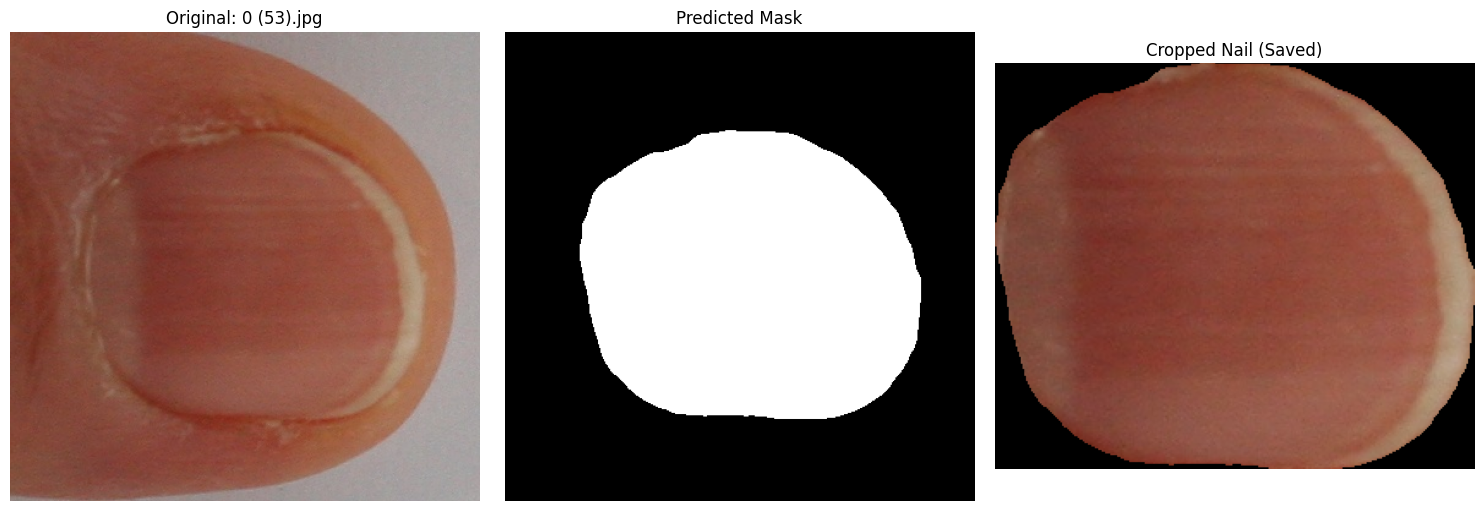


All processed images and masks have been successfully saved to your Google Drive 'output' folder!


In [14]:
import os
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Define your input and output folder paths
folder_name = 'photos'  # Folder containing your input images
folder_path = Path(PROJECT_DIR) / folder_name
output_folder = Path(PROJECT_DIR) / 'output'

# 2. Automatically create the output folder if it doesn't already exist
output_folder.mkdir(parents=True, exist_ok=True)
print(f"Results will be saved to: {output_folder}\n")

# 3. Find all images in the input folder
image_extensions = ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG')
image_files = []
for ext in image_extensions:
    image_files.extend(list(folder_path.glob(ext)))

if len(image_files) == 0:
    print(f"No images found in '{folder_path}'.")
else:
    print(f"Found {len(image_files)} image(s) to process.\n")

    # 4. Loop through, process, display, and save
    for img_path in image_files:
        print(f"Processing: {img_path.name}")

        bgr_image = cv2.imread(str(img_path))
        if bgr_image is None:
            print(f"Could not read {img_path.name}, skipping.")
            continue

        # Run your custom segmenter class
        crop, mask, is_valid = segmenter.crop(bgr_image)
        print(f" -> Validity Check: {is_valid}")

        # SAVE THE RESULTS TO THE OUTPUT FOLDER
        # Save the cropped nail image if found
        if crop is not None:
            crop_filename = output_folder / f"{img_path.stem}_nail_crop.png"
            cv2.imwrite(str(crop_filename), crop)

        # Save the predicted mask (converting 0/1 mask to 0/255 for a clear white-on-black image)
        mask_filename = output_folder / f"{img_path.stem}_mask.png"
        cv2.imwrite(str(mask_filename), mask * 255)

        # Visualize results in the notebook
        rgb_image = cv2.cvtColor(bgr_image, cv2.COLOR_BGR2RGB)
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        axes[0].imshow(rgb_image)
        axes[0].set_title(f"Original: {img_path.name}")
        axes[0].axis('off')

        axes[1].imshow(mask * 255, cmap='gray')
        axes[1].set_title("Predicted Mask")
        axes[1].axis('off')

        if crop is not None:
            axes[2].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
            axes[2].set_title("Cropped Nail (Saved)")
        else:
            axes[2].text(0.5, 0.5, "No Nail Found", ha='center', va='center')
            axes[2].set_title("Cropped Nail")
        axes[2].axis('off')

        plt.tight_layout()
        plt.show()

    print("\nAll processed images and masks have been successfully saved to your Google Drive 'output' folder!")